# LAB 2 – Bài 2: Phân lớp dữ liệu Adult Income (Trang 15–16)
Yêu cầu lập trình: ID3, CART và Naïve Bayes trên dữ liệu thu nhập người trưởng thành ở Hoa Kỳ. Thuộc tính quyết định: `income` (`>50K` / `<=50K`). Cần file `adult.data.csv` và `adult.test.csv`.


In [1]:
HO_TEN = "Lê Quốc Trung"
MSSV = "6451071082"


def in_ten():
    print(f"{HO_TEN} - {MSSV}")


in_ten()

Lê Quốc Trung - 6451071082


## Chuẩn bị: thư viện và hàm dùng chung

In [2]:
%matplotlib inline
import os
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn import tree
from sklearn.naive_bayes import GaussianNB
from sklearn import metrics


import urllib.request

# ID file trên Google Drive (lấy từ link chia sẻ .../file/d/<ID>/view)
FILE_IDS = {
    "adult.data.csv": "1BYKP73pyzphA5YHR1fVvn2A0kBpr09TB",
    "adult.test.csv": "1Vh7e1IBL0SRxjT3gU_v_rnIcAT18griD",
    "heart.csv": "10N9jGzMn-MagDWXORdP-qIpwC3omZJHb",
    "mushrooms.csv": "11OXFpnwUwK_Ka9BFmboMoT9RhTRe3CFW",
    "winequality-red.csv": "1rzLiUi64RLmMV8ApudCt6aJyv_OkhADH",
}


def tai_tu_drive(file_id, ten_luu):
    """Tải file công khai từ Google Drive theo ID và lưu thành ten_luu."""
    url = f"https://drive.google.com/uc?export=download&id={file_id}"
    req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
    with urllib.request.urlopen(req, timeout=120) as r:
        noi_dung = r.read()
    if noi_dung.lstrip()[:15].lower().startswith((b"<!doctype html", b"<html")):
        raise RuntimeError("Drive trả về trang web thay vì file: kiểm tra file đã chia sẻ 'Bất kỳ ai có đường liên kết' chưa.")
    with open(ten_luu, "wb") as f:
        f.write(noi_dung)


def tim_file(ten_file):
    """Trả về đường dẫn file dữ liệu: dùng bản có sẵn trong máy, nếu chưa có thì tải từ Drive theo FILE_IDS."""
    for thu_muc in [".", "data", "/content"]:
        p = os.path.join(thu_muc, ten_file)
        if os.path.isfile(p):
            print("Đã tìm thấy:", p)
            return p
    if ten_file not in FILE_IDS:
        raise FileNotFoundError(f"Không có file '{ten_file}' và cũng không có ID Drive tương ứng.")
    print(f"Đang tải '{ten_file}' từ Google Drive...")
    tai_tu_drive(FILE_IDS[ten_file], ten_file)
    print("Đã tải xong:", ten_file)
    return ten_file


ket_qua = {}   # lưu chỉ số của từng mô hình để so sánh ở Câu 10


def tinh_chi_so(y_true, y_pred, pos_label=None):
    d = {"Accuracy": metrics.accuracy_score(y_true, y_pred)}
    for avg in ("macro", "weighted"):
        p, r, f, _ = metrics.precision_recall_fscore_support(y_true, y_pred, average=avg, zero_division=0)
        d[f"Precision ({avg})"], d[f"Recall ({avg})"], d[f"F1 ({avg})"] = p, r, f
    if pos_label is not None:
        p, r, f, _ = metrics.precision_recall_fscore_support(
            y_true, y_pred, labels=[pos_label], average=None, zero_division=0)
        d[f"Precision [{pos_label}]"], d[f"Recall [{pos_label}]"], d[f"F1 [{pos_label}]"] = p[0], r[0], f[0]
    return d


def danh_gia_mo_hinh(ten, y_test, y_pred, labels, pos_label=None, cmap="Blues"):
    """In accuracy + classification report, vẽ heatmap ma trận nhầm lẫn, lưu chỉ số để so sánh."""
    score = metrics.accuracy_score(y_test, y_pred)
    print("Accuracy:", score)
    print("Report:\n", metrics.classification_report(y_test, y_pred, labels=labels, zero_division=0))
    cm = metrics.confusion_matrix(y_test, y_pred, labels=labels)
    plt.figure(figsize=(8, 8))
    sns.heatmap(cm, annot=True, fmt="d", linewidths=.5, square=True, cmap=cmap,
                xticklabels=labels, yticklabels=labels)
    plt.ylabel("Actual label")
    plt.xlabel("Predicted label")
    plt.title(f"{ten} Accuracy Score: {score:.4f}", size=15)
    plt.show()
    ket_qua[ten] = tinh_chi_so(y_test, y_pred, pos_label)
    return cm


def ve_cay(clf, feature_names, ten_file, max_depth=None, figsize=(50, 24), fontsize=10):
    """Vẽ cây quyết định và lưu thành file PNG (dpi=100)."""
    fig, ax = plt.subplots(figsize=figsize)
    tree.plot_tree(clf, max_depth=max_depth, feature_names=list(feature_names),
                   class_names=[str(c) for c in clf.classes_], filled=True, fontsize=fontsize, ax=ax)
    plt.savefig(ten_file, dpi=100)
    plt.show()
    print("Đã lưu cây vào file:", ten_file)

## Câu 1: Nhập dữ liệu đầu vào, cho biết số lượng dữ liệu huấn luyện và kiểm thử

In [3]:
in_ten()


def doc_csv(duong_dan):
    with open(duong_dan, encoding="utf-8-sig") as f:
        dong_dau = f.readline()
    bo_qua = 1 if dong_dau.startswith("|") else 0   # một số bản có dòng rác đầu file
    return pd.read_csv(duong_dan, skipinitialspace=True, skiprows=bo_qua, encoding="utf-8-sig")


train_raw = doc_csv(tim_file("adult.data.csv"))
test_raw = doc_csv(tim_file("adult.test.csv"))

print("Số lượng dữ liệu huấn luyện (adult.data.csv):", len(train_raw))
print("Số lượng dữ liệu kiểm thử   (adult.test.csv):", len(test_raw))
display(train_raw.head())

Lê Quốc Trung - 6451071082
Đang tải 'adult.data.csv' từ Google Drive...
Đã tải xong: adult.data.csv
Đang tải 'adult.test.csv' từ Google Drive...
Đã tải xong: adult.test.csv
Số lượng dữ liệu huấn luyện (adult.data.csv): 32561
Số lượng dữ liệu kiểm thử   (adult.test.csv): 16281


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


## Câu 2: Tiền xử lý dữ liệu
- Xóa các dòng có dữ liệu trống (ký hiệu `?`).
- Xóa cột `fnlwgt` trong dữ liệu huấn luyện (không có trong dữ liệu kiểm thử).
- Nối dữ liệu huấn luyện và kiểm thử lại với nhau (biến `data`).

In [4]:
in_ten()


def lam_sach(df):
    """Bỏ khoảng trắng thừa, đổi '?' thành NaN rồi xóa các dòng chứa NaN."""
    df = df.copy()
    for cot in df.select_dtypes(exclude="number").columns:
        df[cot] = df[cot].str.strip()
    return df.replace("?", np.nan).dropna()


train = lam_sach(train_raw).drop(columns=["fnlwgt"])
test = lam_sach(test_raw)

# Chuẩn hóa nhãn (một số bản test có dấu '.' ở cuối, vd '<=50K.')
for df in (train, test):
    df["income"] = df["income"].str.replace(r"[\\.\s]", "", regex=True)

n_train, n_test = len(train), len(test)
print("Number of training data:", n_train)
print("Number of test data:", n_test)

data = pd.concat([train, test], ignore_index=True)
data.info()

Lê Quốc Trung - 6451071082
Number of training data: 30162
Number of test data: 15060
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45222 entries, 0 to 45221
Data columns (total 14 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   age             45222 non-null  int64 
 1   workclass       45222 non-null  object
 2   education       45222 non-null  object
 3   education-num   45222 non-null  int64 
 4   marital-status  45222 non-null  object
 5   occupation      45222 non-null  object
 6   relationship    45222 non-null  object
 7   race            45222 non-null  object
 8   sex             45222 non-null  object
 9   capital-gain    45222 non-null  int64 
 10  capital-loss    45222 non-null  int64 
 11  hours-per-week  45222 non-null  int64 
 12  native-country  45222 non-null  object
 13  income          45222 non-null  object
dtypes: int64(5), object(9)
memory usage: 4.8+ MB


## Câu 3: Khảo sát độ tương đồng giữa các cột bằng công thức Pearson
Vẽ heatmap (màu càng đậm → mức độ tương đồng càng thấp). Sau đó tự động tìm các cặp cột **feature** có |r| vượt ngưỡng và loại bỏ.

Lê Quốc Trung - 6451071082


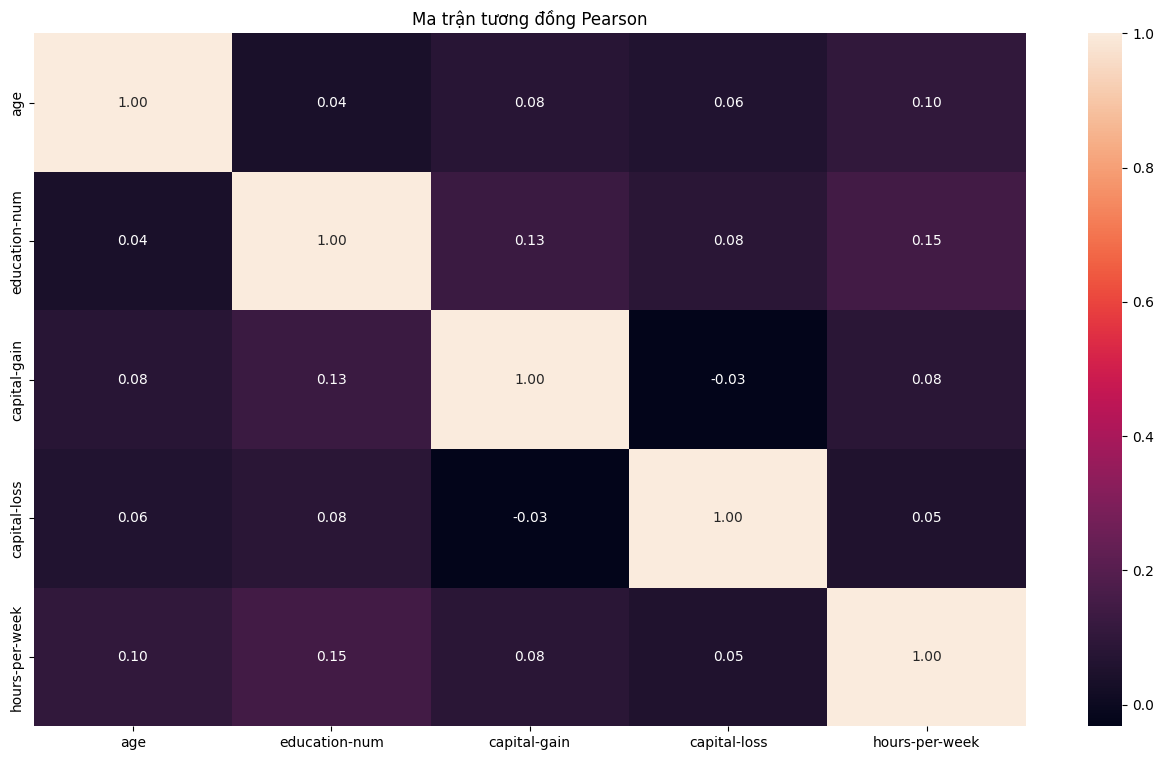

In [5]:
in_ten()
NHAN = "income"   # thuộc tính quyết định

plt.figure(figsize=(16, 9))
sns.heatmap(data.corr(method="pearson", numeric_only=True), annot=True, fmt=".2f")
plt.title("Ma trận tương đồng Pearson")
plt.show()

In [6]:
in_ten()
NGUONG_PEARSON = 0.8   # |r| > ngưỡng này được xem là tương đồng cao

corr = data.drop(columns=[NHAN]).corr(method="pearson", numeric_only=True).abs()
tam_giac_tren = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
cap_cao = [(a, b, round(float(tam_giac_tren.loc[a, b]), 3))
           for a in tam_giac_tren.index for b in tam_giac_tren.columns
           if pd.notna(tam_giac_tren.loc[a, b]) and tam_giac_tren.loc[a, b] > NGUONG_PEARSON]
cot_loai = sorted({b for _, b, _ in cap_cao})

if cap_cao:
    print("Các cặp cột tương đồng cao:", cap_cao)
    print("Loại bỏ các cột:", cot_loai)
else:
    print(f"Không có cặp cột nào có |r| > {NGUONG_PEARSON} => không cần loại bỏ cột nào.")

data = data.drop(columns=cot_loai)
print("Các cột còn lại:", list(data.columns))

Lê Quốc Trung - 6451071082
Không có cặp cột nào có |r| > 0.8 => không cần loại bỏ cột nào.
Các cột còn lại: ['age', 'workclass', 'education', 'education-num', 'marital-status', 'occupation', 'relationship', 'race', 'sex', 'capital-gain', 'capital-loss', 'hours-per-week', 'native-country', 'income']


## Câu 4: Tách các cột thành hai phần
`features` chứa các thuộc tính bình thường, `labels` chứa riêng thuộc tính quyết định.

In [7]:
in_ten()
features = data.drop(NHAN, axis=1)
labels = data[NHAN]
print("features:", features.shape, "| labels:", labels.shape)
print(labels.value_counts())

Lê Quốc Trung - 6451071082
features: (45222, 13) | labels: (45222,)
income
<=50K    34014
>50K     11208
Name: count, dtype: int64


## Câu 5: Chuyển các cột không phải dạng số về one-hot vector
Xác định các cột không phải dạng số rồi dùng `pd.get_dummies`.

In [8]:
in_ten()
cot_chu = features.select_dtypes(exclude="number").columns
print("Các cột không phải dạng số:", list(cot_chu))

if len(cot_chu) > 0:
    features_onehot = pd.get_dummies(features, columns=cot_chu, dtype=int)
else:
    features_onehot = features.copy()
    print("=> Tất cả các cột đều là dạng số, không cần chuyển one-hot.")

print("Kích thước sau khi xử lý:", features_onehot.shape)
display(features_onehot.head())

Lê Quốc Trung - 6451071082
Các cột không phải dạng số: ['workclass', 'education', 'marital-status', 'occupation', 'relationship', 'race', 'sex', 'native-country']
Kích thước sau khi xử lý: (45222, 103)


,age,education-num,capital-gain,capital-loss,hours-per-week,workclass_Federal-gov,workclass_Local-gov,workclass_Private,workclass_Self-emp-inc,workclass_Self-emp-not-inc,...,native-country_Portugal,native-country_Puerto-Rico,native-country_Scotland,native-country_South,native-country_Taiwan,native-country_Thailand,native-country_Trinadad&Tobago,native-country_United-States,native-country_Vietnam,native-country_Yugoslavia
0,39,13,2174,0,40,0,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0
1,50,13,0,0,13,0,0,0,0,1,...,0,0,0,0,0,0,0,1,0,0
2,38,9,0,0,40,0,0,1,0,0,...,0,0,0,0,0,0,0,1,0,0
3,53,7,0,0,40,0,0,1,0,0,...,0,0,0,0,0,0,0,1,0,0
4,28,13,0,0,40,0,0,1,0,0,...,0,0,0,0,0,0,0,0,0,0


## Câu 6: Tách dữ liệu thành hai phần huấn luyện và kiểm thử như ban đầu
Dùng `n_train` (số dòng huấn luyện sau tiền xử lý) để cắt đúng vị trí.

In [9]:
in_ten()
X_train = features_onehot.iloc[:n_train]
X_test = features_onehot.iloc[n_train:]
y_train = labels.iloc[:n_train]
y_test = labels.iloc[n_train:]

LOP = sorted(labels.unique())
print("X_train:", X_train.shape, "| X_test:", X_test.shape)
print("Các lớp:", LOP)

Lê Quốc Trung - 6451071082
X_train: (30162, 103) | X_test: (15060, 103)
Các lớp: ['<=50K', '>50K']


## Câu 7: Xây dựng cây ID3 (`criterion="entropy"` – phân nhánh theo information gain)
Gồm 3 phần: huấn luyện + dự đoán → kiểm thử bằng ma trận nhầm lẫn → biểu diễn cây.

In [10]:
in_ten()
clf_id3 = tree.DecisionTreeClassifier(criterion="entropy", random_state=0)
clf_id3.fit(X_train, y_train)          # huấn luyện
id3_pred = clf_id3.predict(X_test)     # dự đoán trên dữ liệu kiểm thử
print("Số nút:", clf_id3.tree_.node_count, "| số lá:", clf_id3.get_n_leaves(), "| độ sâu:", clf_id3.get_depth())

Lê Quốc Trung - 6451071082
Số nút: 10653 | số lá: 5327 | độ sâu: 51


Lê Quốc Trung - 6451071082
Accuracy: 0.8175298804780876
Report:
               precision    recall  f1-score   support

       <=50K       0.88      0.88      0.88     11360
        >50K       0.63      0.62      0.62      3700

    accuracy                           0.82     15060
   macro avg       0.75      0.75      0.75     15060
weighted avg       0.82      0.82      0.82     15060



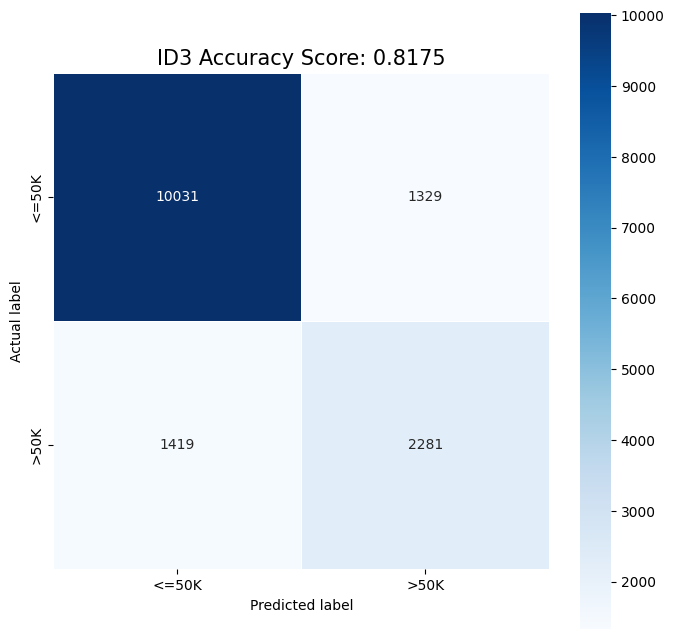

Ma trận nhầm lẫn (hàng = thực tế, cột = dự đoán):
[[10031  1329]
 [ 1419  2281]]


In [11]:
in_ten()
id3_cm = danh_gia_mo_hinh("ID3", y_test, id3_pred, LOP, pos_label='>50K', cmap="Blues")
print("Ma trận nhầm lẫn (hàng = thực tế, cột = dự đoán):")
print(id3_cm)

Lê Quốc Trung - 6451071082


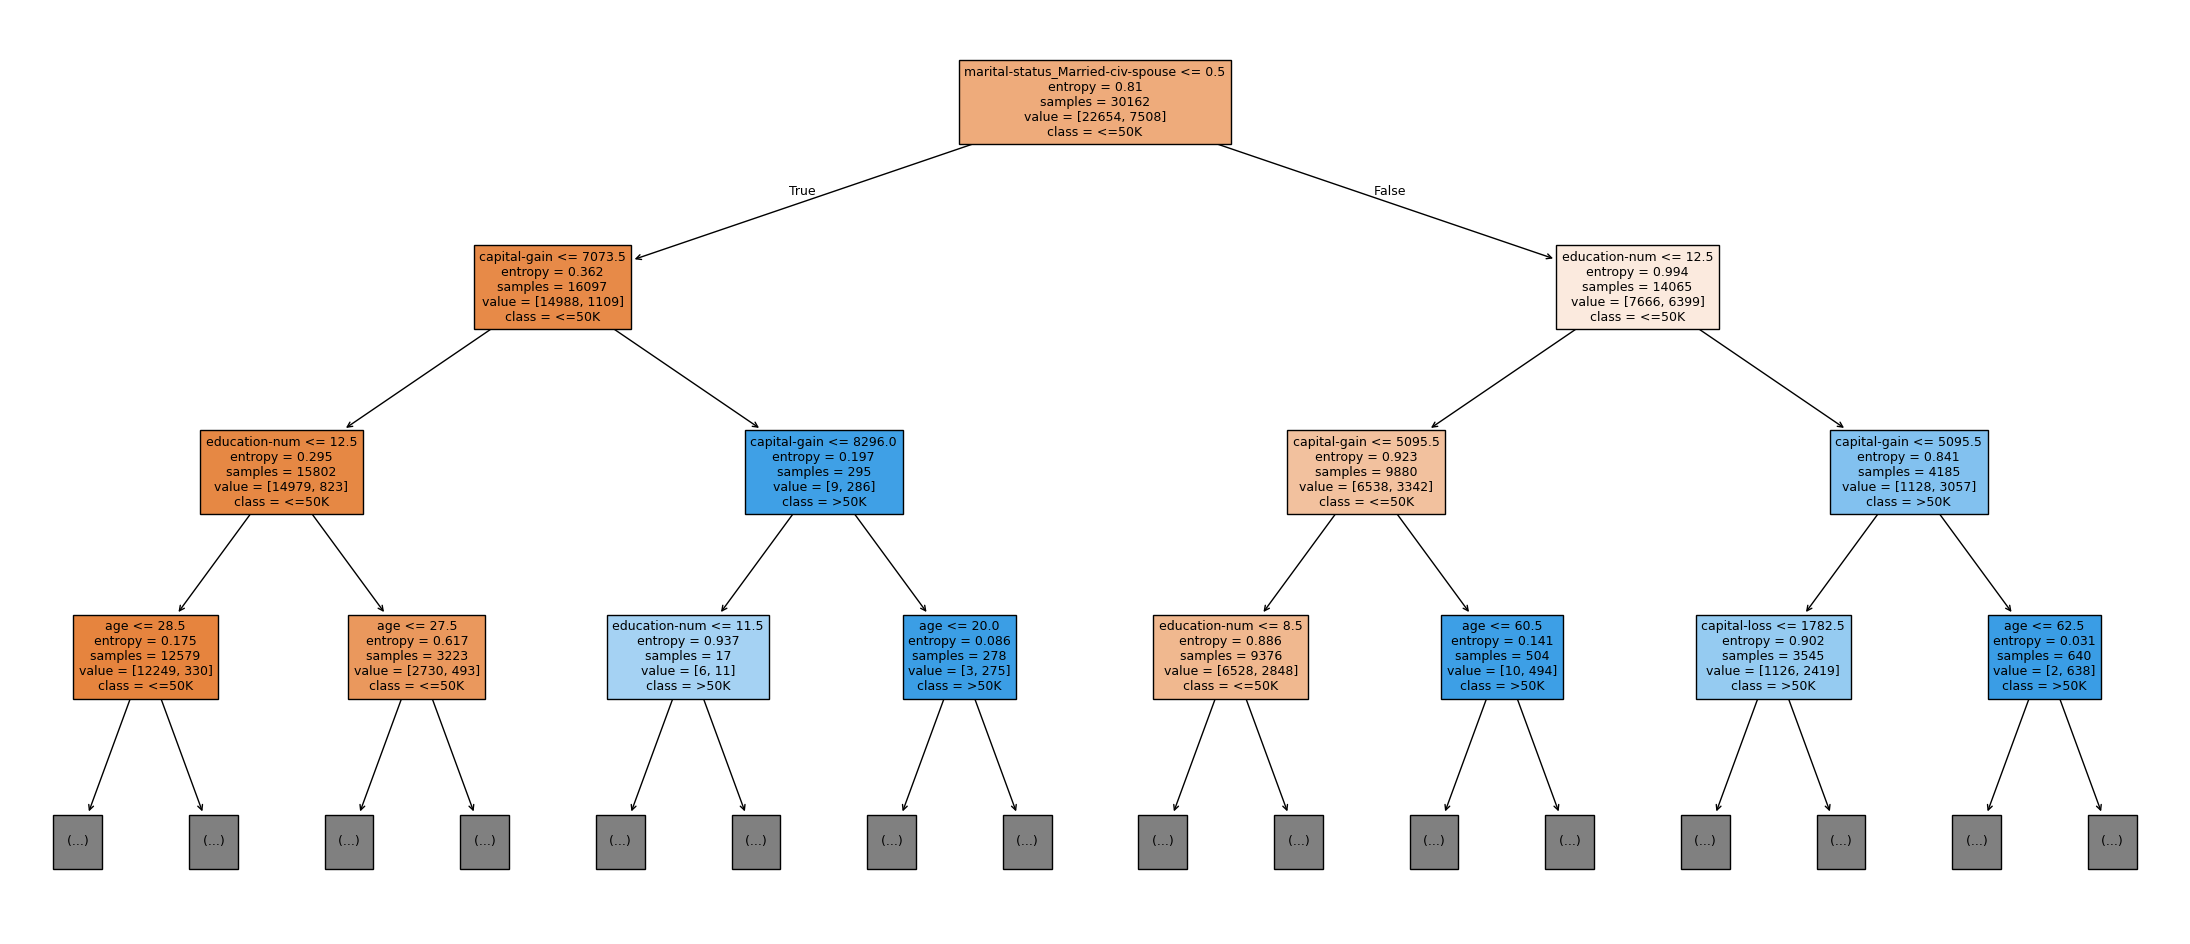

Đã lưu cây vào file: cay_ID3_rut_gon.png


In [12]:
in_ten()
# Cây rút gọn (3 mức trên cùng) để đọc được trên màn hình
ve_cay(clf_id3, X_train.columns, "cay_ID3_rut_gon.png", max_depth=3, figsize=(28, 12), fontsize=9)

Lê Quốc Trung - 6451071082


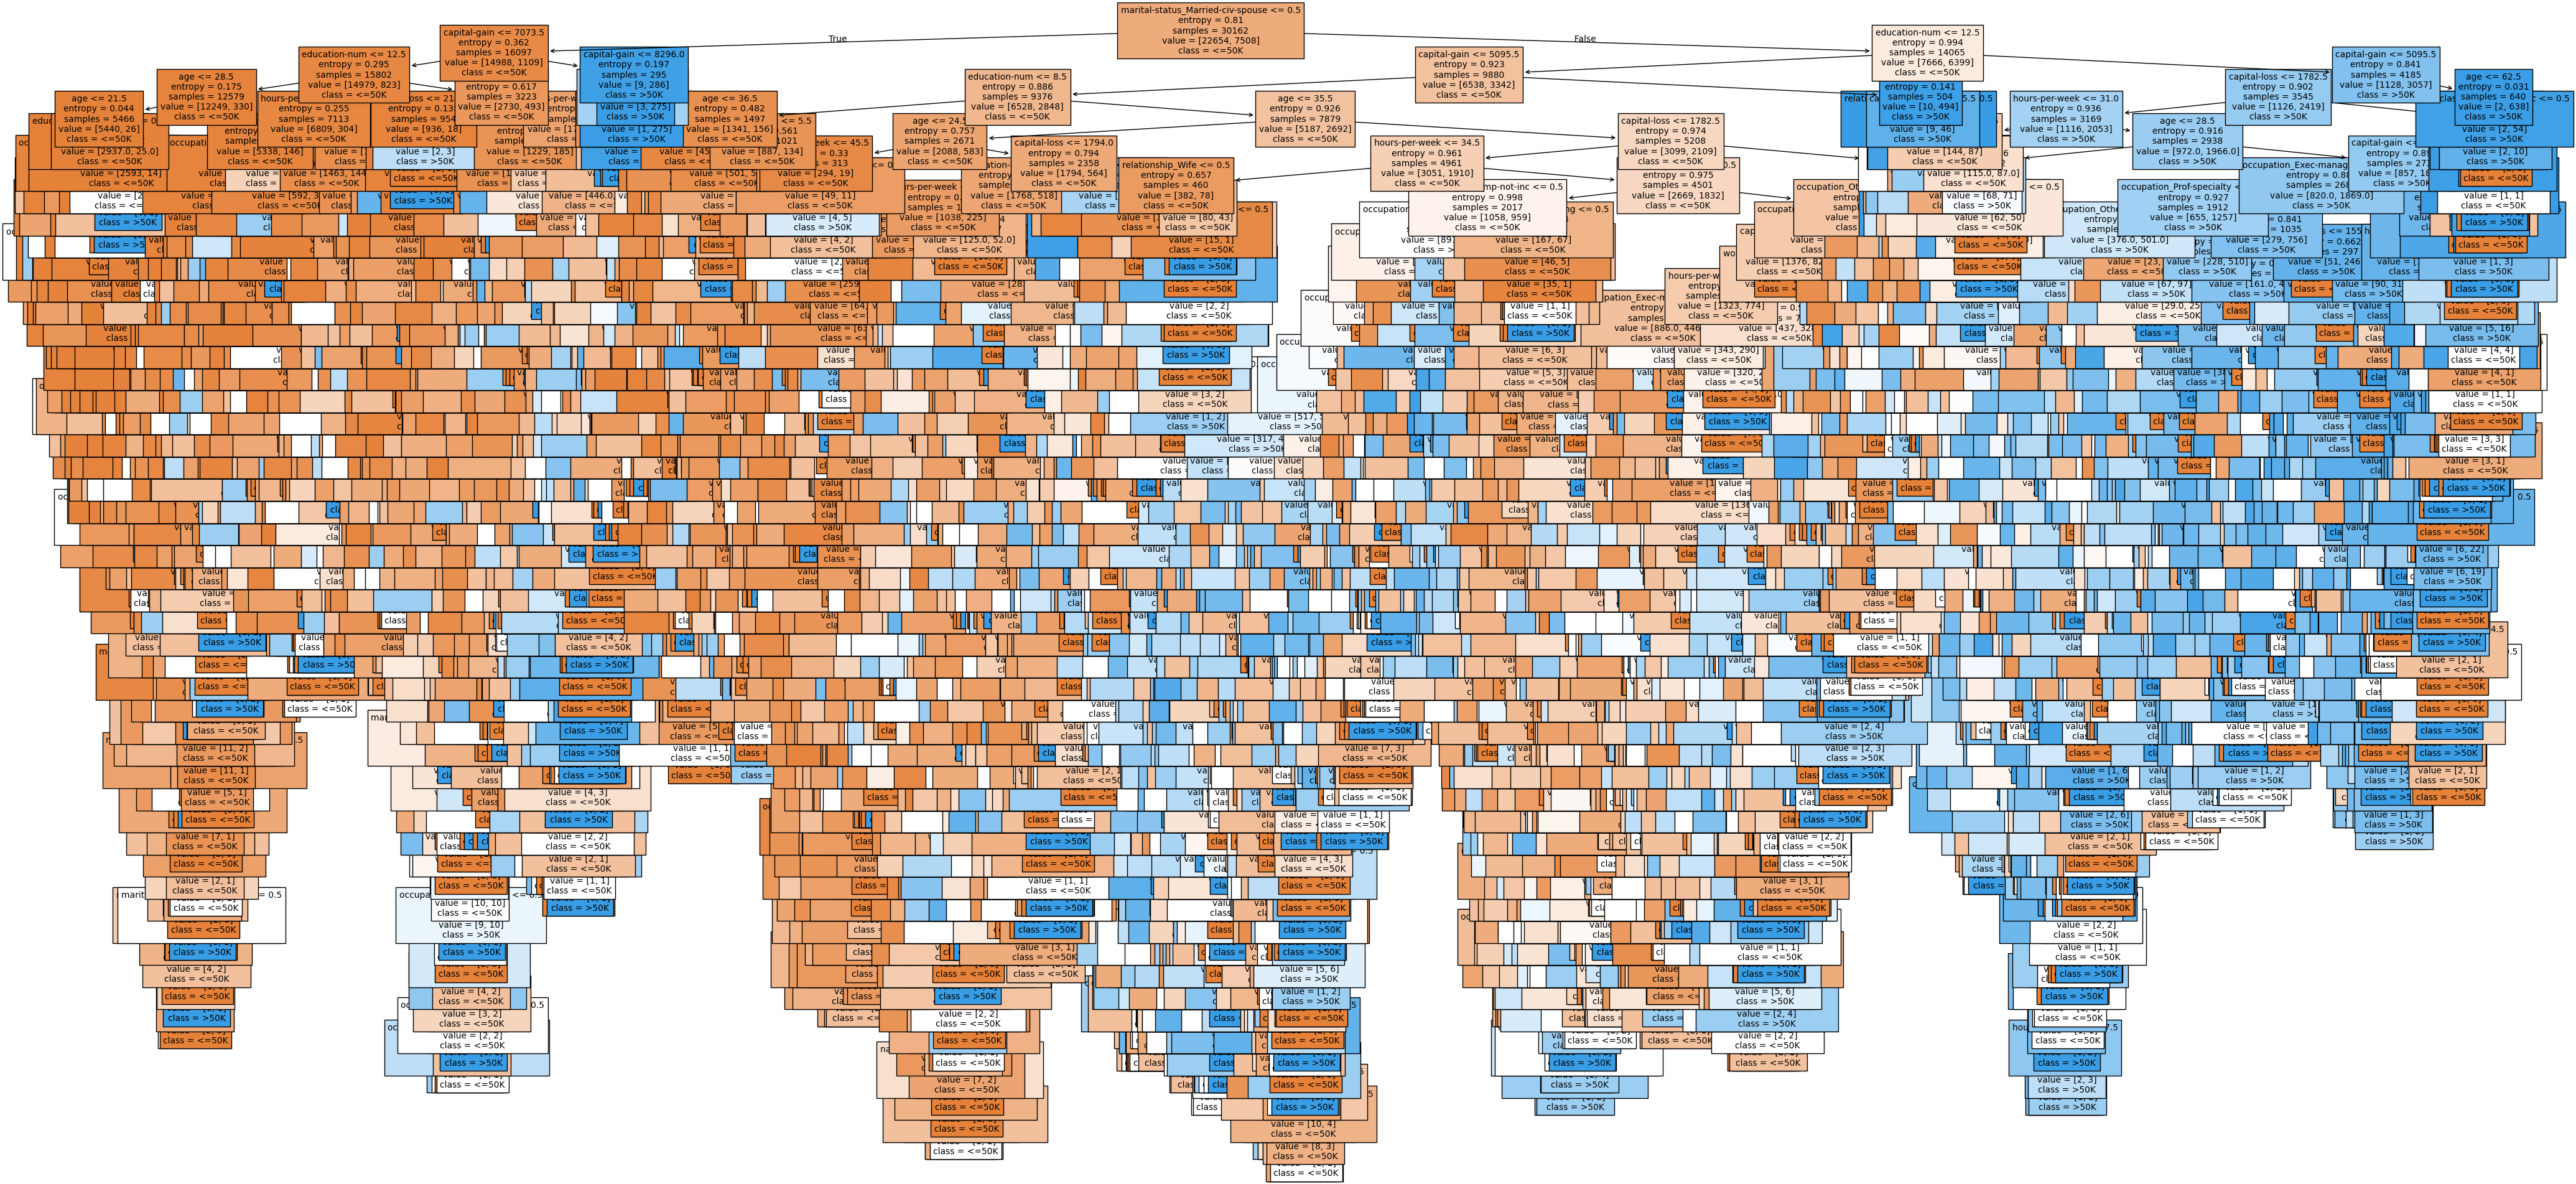

Đã lưu cây vào file: cay_ID3.png


In [13]:
in_ten()
# Cây đầy đủ (ảnh rất lớn; đặt False nếu máy chậm/thiếu RAM)
VE_CAY_DAY_DU = True
if VE_CAY_DAY_DU:
    ve_cay(clf_id3, X_train.columns, "cay_ID3.png", figsize=(50, 24), fontsize=10)

## Câu 8: Xây dựng cây CART (`criterion="gini"`)
Thực hiện tương tự Câu 7, thay `criterion="gini"`.

In [14]:
in_ten()
clf_cart = tree.DecisionTreeClassifier(criterion="gini", random_state=0)
clf_cart.fit(X_train, y_train)
cart_pred = clf_cart.predict(X_test)
print("Số nút:", clf_cart.tree_.node_count, "| số lá:", clf_cart.get_n_leaves(), "| độ sâu:", clf_cart.get_depth())

Lê Quốc Trung - 6451071082
Số nút: 10661 | số lá: 5331 | độ sâu: 46


Lê Quốc Trung - 6451071082
Accuracy: 0.8122841965471448
Report:
               precision    recall  f1-score   support

       <=50K       0.87      0.88      0.88     11360
        >50K       0.62      0.60      0.61      3700

    accuracy                           0.81     15060
   macro avg       0.75      0.74      0.74     15060
weighted avg       0.81      0.81      0.81     15060



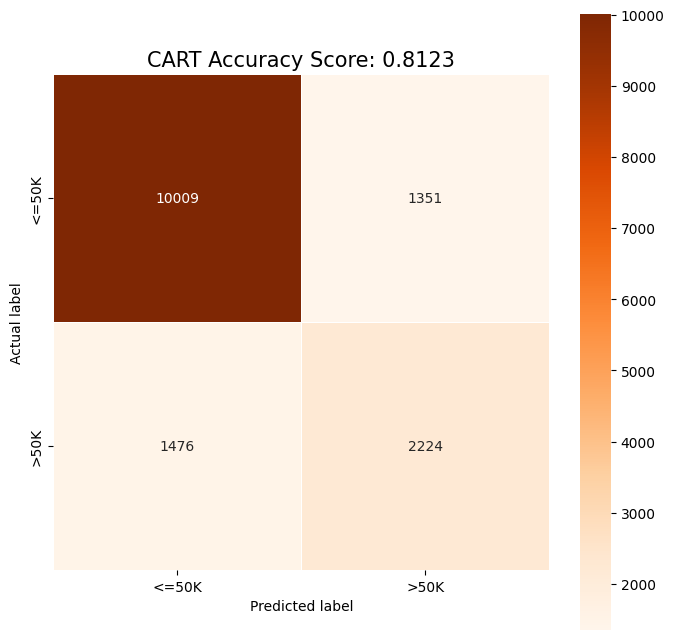

Ma trận nhầm lẫn (hàng = thực tế, cột = dự đoán):
[[10009  1351]
 [ 1476  2224]]


In [15]:
in_ten()
cart_cm = danh_gia_mo_hinh("CART", y_test, cart_pred, LOP, pos_label='>50K', cmap="Oranges")
print("Ma trận nhầm lẫn (hàng = thực tế, cột = dự đoán):")
print(cart_cm)

Lê Quốc Trung - 6451071082


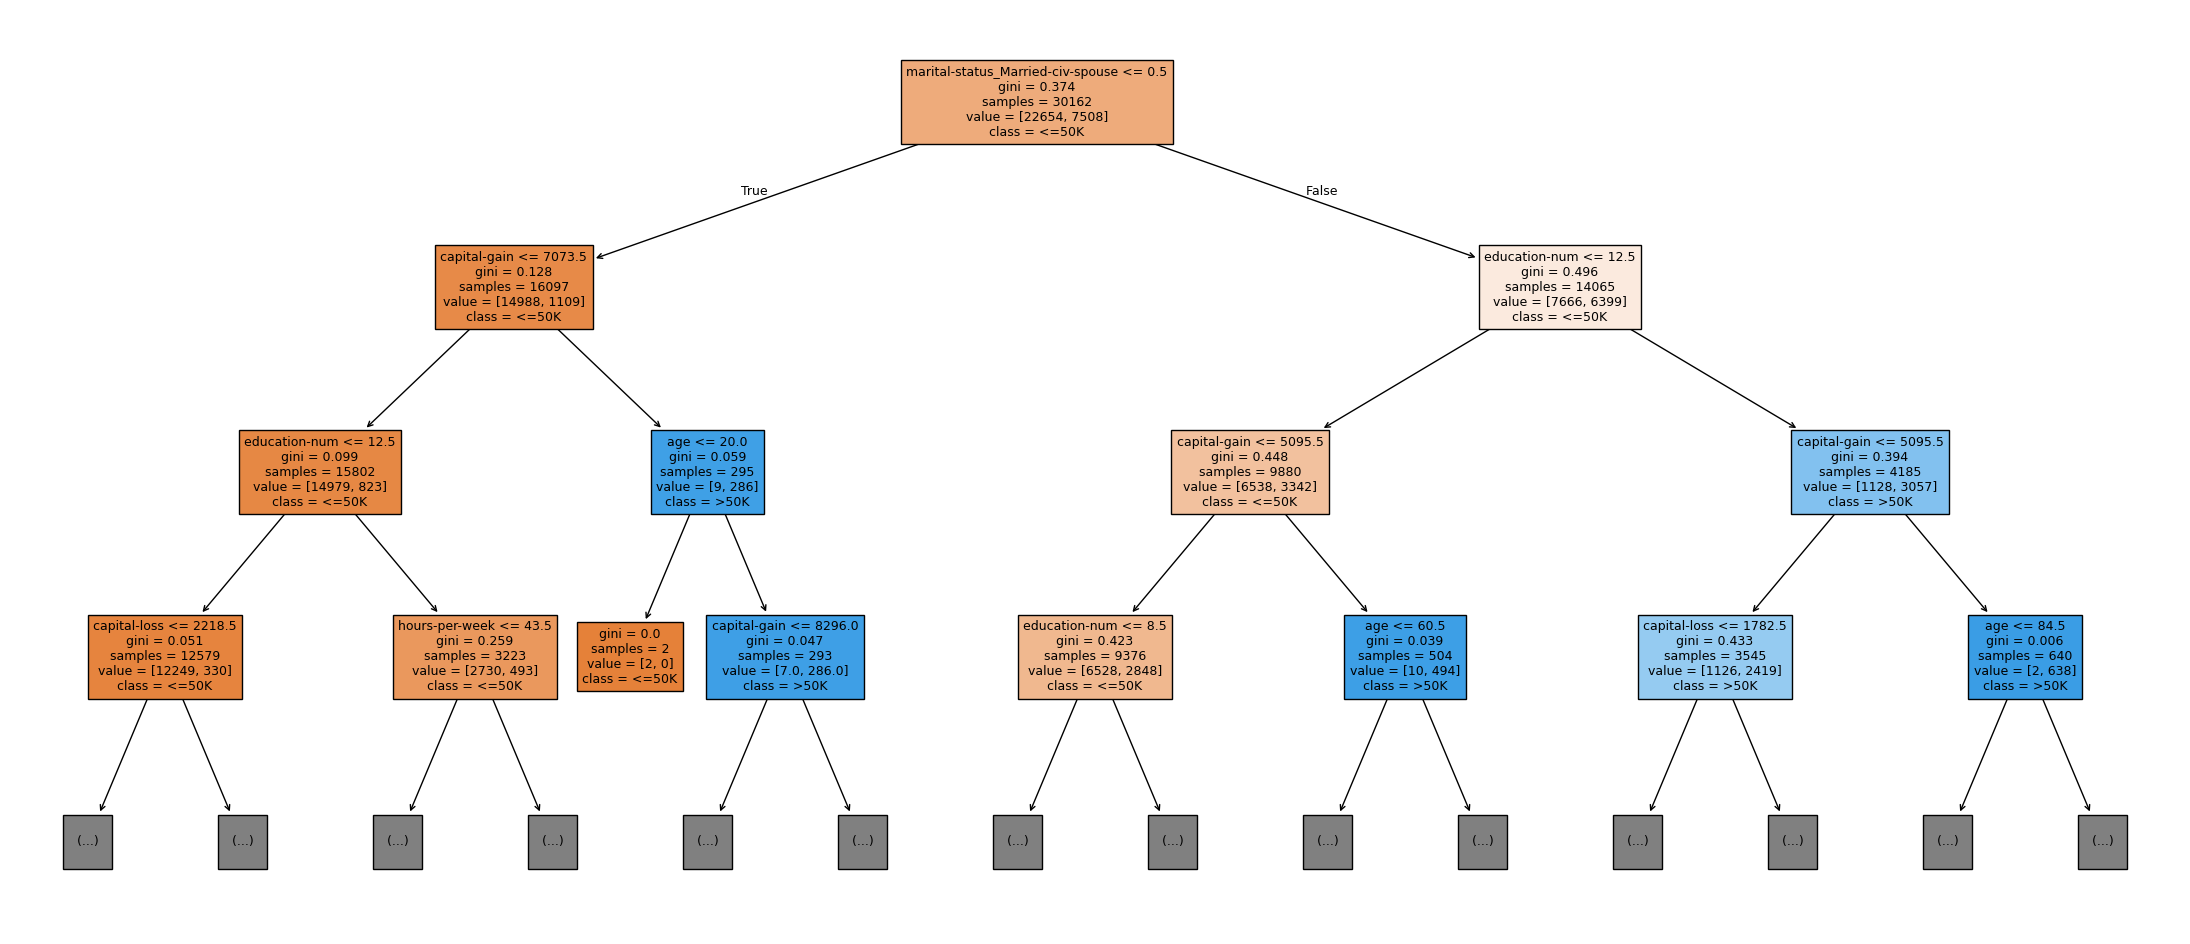

Đã lưu cây vào file: cay_CART_rut_gon.png


In [16]:
in_ten()
ve_cay(clf_cart, X_train.columns, "cay_CART_rut_gon.png", max_depth=3, figsize=(28, 12), fontsize=9)

Lê Quốc Trung - 6451071082


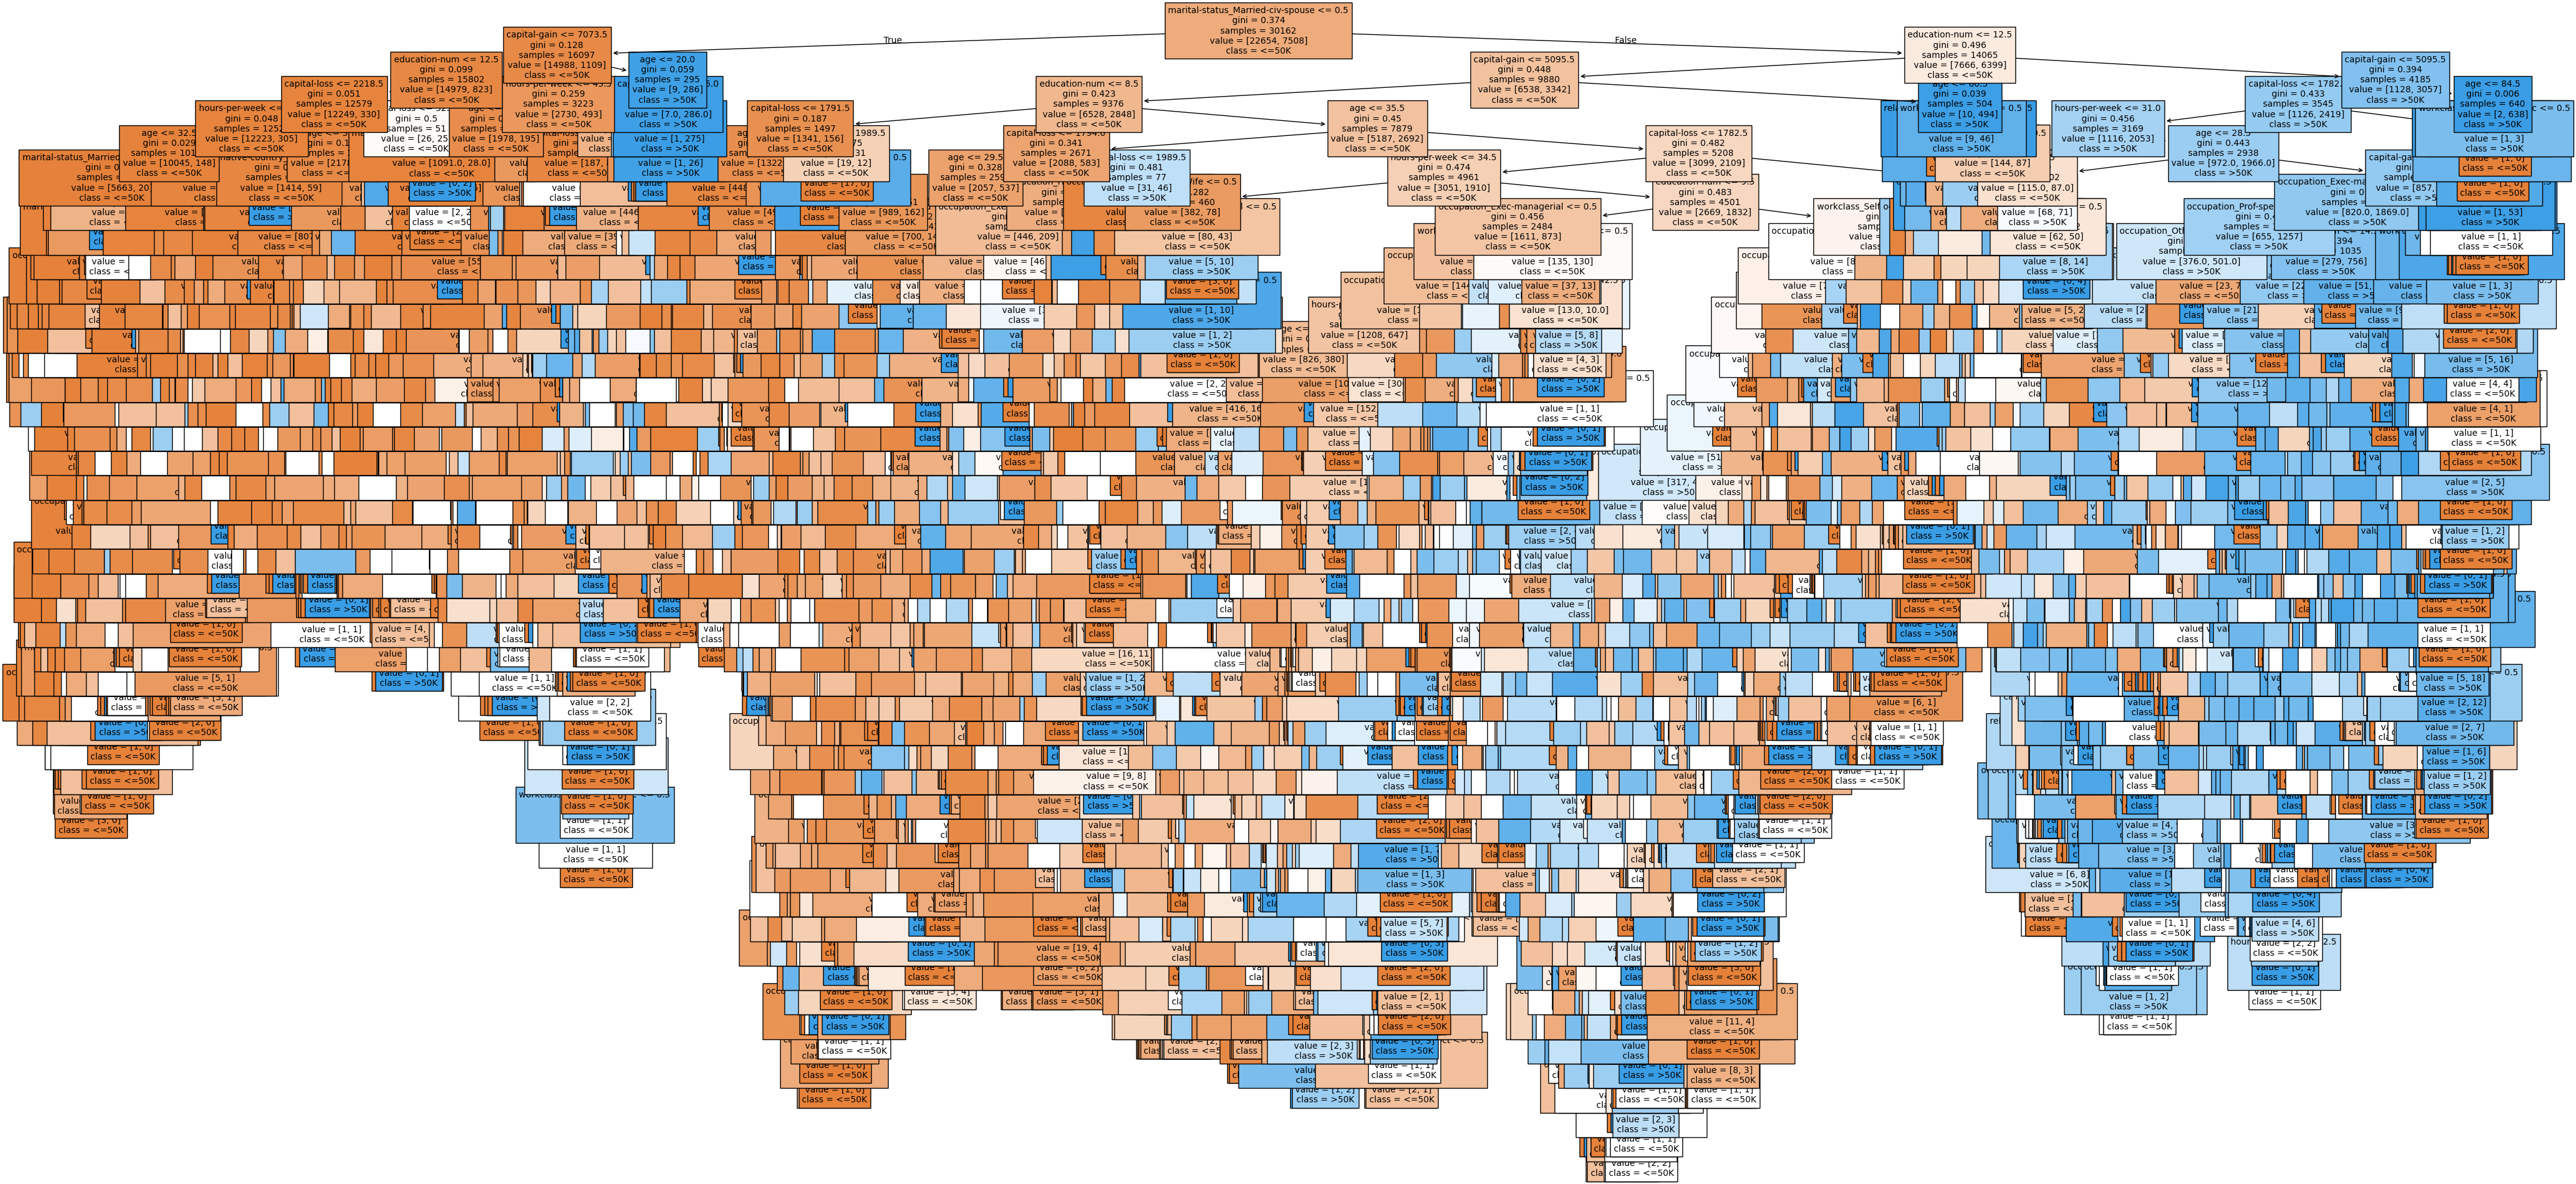

Đã lưu cây vào file: cay_CART.png


In [17]:
in_ten()
VE_CAY_DAY_DU = True
if VE_CAY_DAY_DU:
    ve_cay(clf_cart, X_train.columns, "cay_CART.png", figsize=(50, 24), fontsize=10)

## Câu 9: Xây dựng mô hình phân lớp Naïve Bayes (`GaussianNB`)

In [18]:
in_ten()
gnb = GaussianNB()
bayes_pred = gnb.fit(X_train, y_train).predict(X_test)

Lê Quốc Trung - 6451071082


Lê Quốc Trung - 6451071082
Accuracy: 0.8029216467463479
Report:
               precision    recall  f1-score   support

       <=50K       0.93      0.80      0.86     11360
        >50K       0.57      0.82      0.67      3700

    accuracy                           0.80     15060
   macro avg       0.75      0.81      0.76     15060
weighted avg       0.84      0.80      0.81     15060



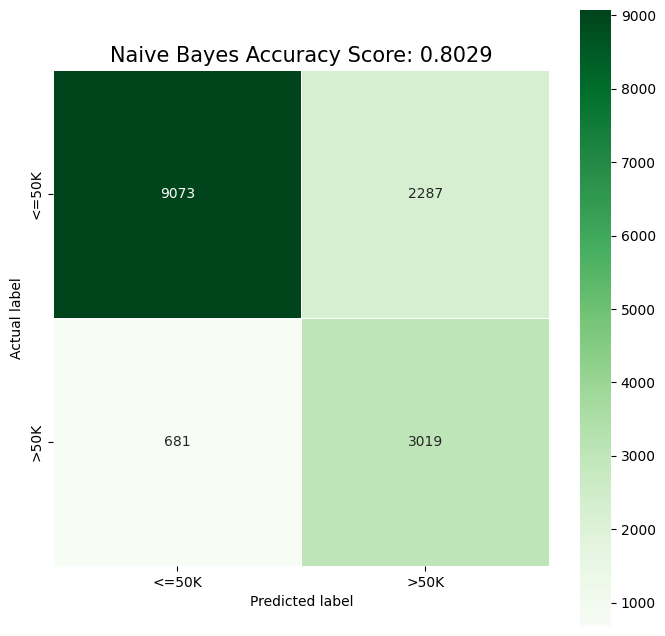

Ma trận nhầm lẫn (hàng = thực tế, cột = dự đoán):
[[9073 2287]
 [ 681 3019]]


In [19]:
in_ten()
bayes_cm = danh_gia_mo_hinh("Naive Bayes", y_test, bayes_pred, LOP, pos_label='>50K', cmap="Greens")
print("Ma trận nhầm lẫn (hàng = thực tế, cột = dự đoán):")
print(bayes_cm)

## Câu 10: So sánh kết quả của các mô hình

Lê Quốc Trung - 6451071082


,Accuracy,Precision (macro),Recall (macro),F1 (macro),Precision (weighted),Recall (weighted),F1 (weighted),Precision [>50K],Recall [>50K],F1 [>50K]
ID3,0.8175,0.7540,0.7497,0.7518,0.8161,0.8175,0.8168,0.6319,0.6165,0.6241
CART,0.8123,0.7468,0.7411,0.7438,0.8102,0.8123,0.8112,0.6221,0.6011,0.6114
Naive Bayes,0.8029,0.7496,0.8073,0.7649,0.8414,0.8029,0.8130,0.5690,0.8159,0.6704


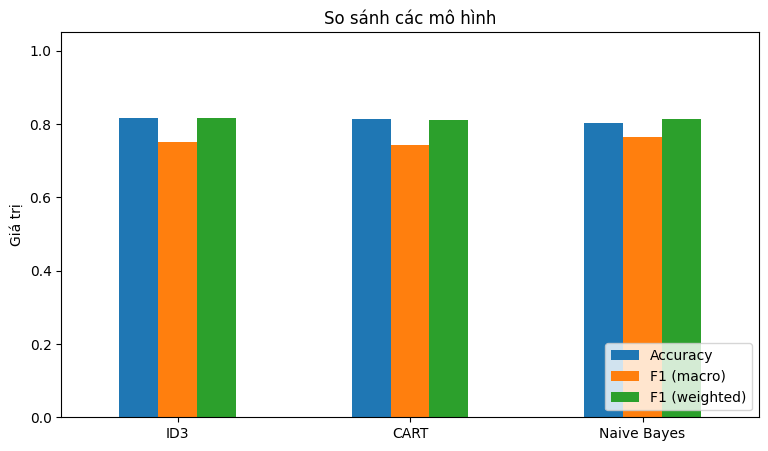

Mô hình có Accuracy cao nhất  : ID3 (0.8175)
Mô hình có F1 (macro) cao nhất: Naive Bayes (0.7649)


In [20]:
in_ten()
bang_ss = pd.DataFrame(ket_qua).T.round(4)
display(bang_ss)

bang_ss[["Accuracy", "F1 (macro)", "F1 (weighted)"]].plot(kind="bar", figsize=(9, 5), rot=0)
plt.title("So sánh các mô hình")
plt.ylabel("Giá trị")
plt.ylim(0, 1.05)
plt.legend(loc="lower right")
plt.show()

print("Mô hình có Accuracy cao nhất  :", bang_ss["Accuracy"].idxmax(), f"({bang_ss['Accuracy'].max():.4f})")
print("Mô hình có F1 (macro) cao nhất:", bang_ss["F1 (macro)"].idxmax(), f"({bang_ss['F1 (macro)'].max():.4f})")

### Nhận xét (đối chiếu với bảng số liệu ở trên rồi chỉnh lại cho khớp kết quả chạy thực tế)
- Cây ID3/CART không giới hạn độ sâu nên fit rất sát dữ liệu huấn luyện (nhiều nút, nhiều lá) → có xu hướng **overfit**; có thể cải thiện bằng `max_depth`, `min_samples_leaf` hoặc cắt tỉa (`ccp_alpha`).
- `GaussianNB` giả định các thuộc tính độc lập và có phân phối chuẩn, trong khi dữ liệu sau one-hot là 0/1 → giả định này không thật sự phù hợp; thường **recall** của lớp `>50K` cao hơn nhưng **precision** thấp hơn so với cây.
- Dữ liệu **mất cân bằng** (lớp `<=50K` chiếm đa số) nên không chỉ nhìn Accuracy mà cần xem Precision/Recall/F1 của lớp `>50K`.
- ID3 (entropy) và CART (gini) cho kết quả gần nhau vì hai tiêu chí đo độ tạp (impurity) rất tương tự.